# Imports

In [1]:
import subprocess
import os
import glob
import sys
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from rstools import RSoftCircuit

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
import linecache

from tqdm import tqdm

# 2x2 MMI single input fiber mode injection

Scan in wavelength and phase

In [ ]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = "2x2MMI_OneInput_scan_Wav_Phase"
filename = "2x2MMI_OneInput.ind"
wav_arr = np.linspace(1.48, 1.62, 51)
phase_arr = np.linspace(0, 180, 51)

# Make scan save directory if it doesn't exist
os.makedirs(f"{working_dir}/{save_dir}/", exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    for phase in tqdm(phase_arr, desc=f"Phase loop (Wavelength: {wav} microns)", position=1, leave=False):
        # Set wavelength and phase in .ind file
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.write(working_dir+filename)
        
        # Define the command and arguments
        wav_str = f"{wav:0.3f}".replace(".", "p")
        phase_str = f"{phase:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{save_dir}_Wav{wav_str}_Phase{phase_str}", "wait=0"]
    
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

Phase loop (Wavelength: 1.48 microns):  65%|███████████████████████████▊               | 33/51 [03:54<02:01,  6.76s/it]

# 2x2 MMI double input

Inject

In [6]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = "2x2MMI_OneInput_scan_Wav_Phase"
filename = "2x2MMI_OneInput.ind"
wav_arr = np.linspace(1.48, 1.62, 51)
phase_arr = np.linspace(0, 180, 51)

wav, phase = wav_arr[0], phase_arr[0]

c = RSoftCircuit()
c.read(working_dir+filename)
dir(c)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__swig_destroy__',
 '__weakref__',
 'add_arc',
 'add_arcV',
 'add_circle',
 'add_circleV',
 'add_circuitref',
 'add_circuitrefV',
 'add_lens',
 'add_lensV',
 'add_mark',
 'add_markV',
 'add_material',
 'add_materialV',
 'add_monitor',
 'add_monitorV',
 'add_polygon',
 'add_polygonV',
 'add_portmonitor',
 'add_sbend',
 'add_sbendV',
 'add_segment',
 'add_segmentV',
 'add_textblock',
 'add_textblockV',
 'add_vertex',
 'attach',
 'attachV',
 'delete_symbol',
 'load_settings',
 'read',
 'set_default_tags',
 'set_exports',
 'set_symbol',
 'this',
 'thisown',
 'write']

In [24]:


wav = read_symbol(working_dir+filename, "free_space_wavelength")
phase = read_symbol(working_dir+filename, "PhaseShift")
TaperGap = read_symbol(working_dir+filename, "TaperGap")
TaperWidth = read_symbol(working_dir+filename, "TaperWidth")
BendOffset = read_symbol(working_dir+filename, "BendOffset")

wav, phase, TaperGap, TaperWidth,BendOffset

(1.5136, 129.6, 7.0, 5.0, 15.0)

# Apply phase shift in one output and scan tricoupler in wavelength and phase

In [12]:
# Tricoupler input parameters
TaperGap, TaperWidth, BendOffset = 7, 5, 15
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset
waveguide_width, waveguide_height = 3.4, 3.4

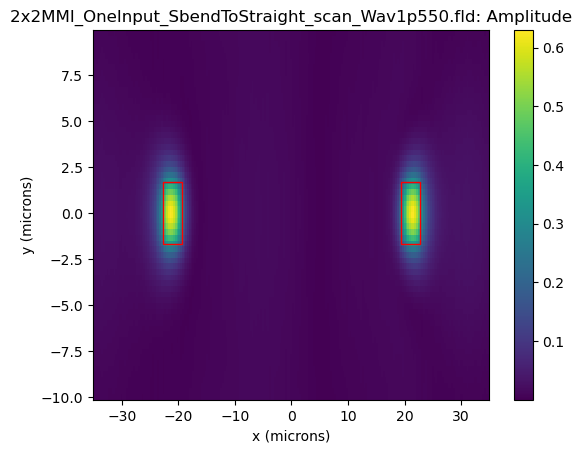

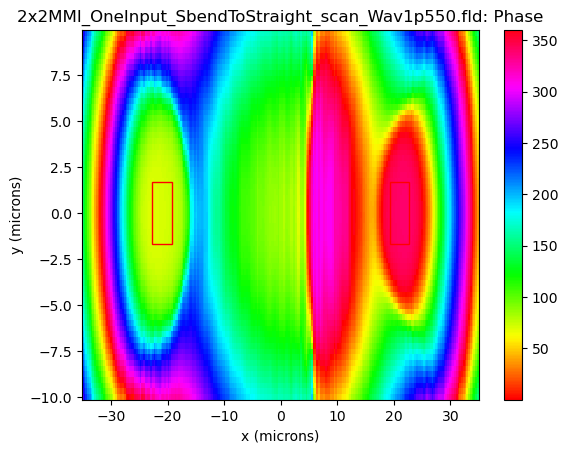

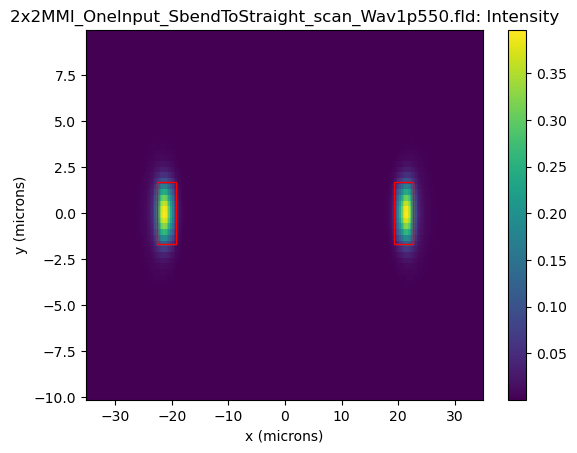

0.39652964643599997

In [101]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_SbendToStraight\\"
save_dir = "2x2MMI_OneInput_scan_Wav"
filenames_field = glob.glob(working_dir+save_dir+f"\\{save_dir}1p550.fld")

field = np.genfromtxt(filenames_field[0], skip_header=4)
n_rows, n_cols = np.shape(field)
field_amp, field_phase = field[:, ::2].T, field[:, 1::2].T
x_line = linecache.getline(filenames_field[0], 3)
y_line = linecache.getline(filenames_field[0], 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

field = field_amp*np.exp(1j*field_phase*np.pi/180)
intensity = np.absolute(field)**2.

fig, ax = plt.subplots()
im = plt.pcolormesh(x, y, field_amp)
square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
ax.add_patch(square_left)
ax.add_patch(square_right)
plt.title(filenames_field[0].split('\\')[-1] + ": Amplitude")
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

fig, ax = plt.subplots()
im = plt.pcolormesh(x, y, field_phase, cmap='hsv')
square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
ax.add_patch(square_left)
ax.add_patch(square_right)
plt.title(filenames_field[0].split('\\')[-1] + ": Phase")
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

fig, ax = plt.subplots()
im = plt.pcolormesh(x, y, intensity)
square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
ax.add_patch(square_left)
ax.add_patch(square_right)
plt.title(filenames_field[0].split('\\')[-1] + ": Intensity")
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

np.max(intensity)

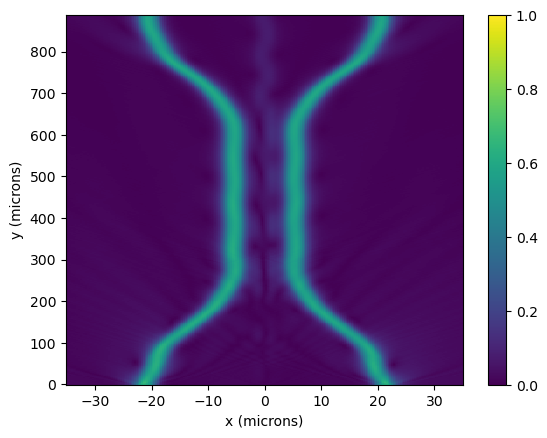

In [11]:
# filename = working_dir+save_dir+"\\2x2MMI_OneInput_scan_Wav1p550_xz.dat"
filename = "C:\\Users\\runner\\ActivePIC\\Device11_4a_1x3Tricoupler\\Device11_4a_1x3Tricoupler_scan_Wav_Phase\\Device11_4a_1x3Tricoupler_scan_Wav1p550_Phase259p200_xz.dat"
data = np.genfromtxt(filename, delimiter='', skip_header=4).T
x_line = linecache.getline(filename, 3)
y_line = linecache.getline(filename, 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

plt.figure()
im = plt.pcolormesh(x, y, data, vmin=0, vmax=1)
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

(227,) (394,) (394,)


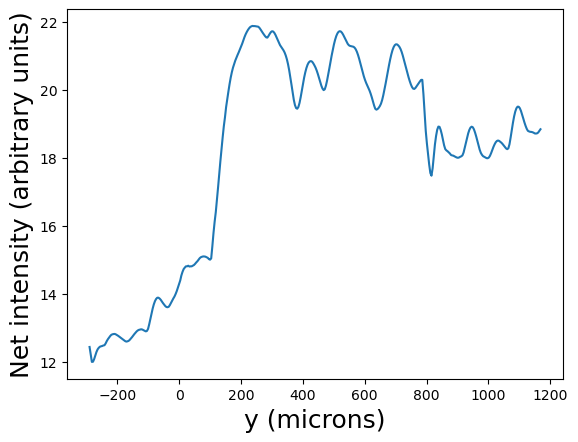

In [72]:
y_profile = np.sum(data, axis=1)
print(np.shape(x), np.shape(y), np.shape(y_profile))

plt.figure()
plt.plot(y, y_profile)
plt.xlabel('y (microns)', fontsize=18)
plt.ylabel('Net intensity (arbitrary units)', fontsize=18)
plt.show()

In [46]:
TaperGap, TaperWidth, TaperLength, BendOffset, BendLength = 7, 5, 100, 15, 289.4391128
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset
MMISlabWidth, MMISlabLength = 17, 682
waveguide_width, waveguide_height = 3.4, 3.4

In [74]:
tricoupler_right_x

21.0

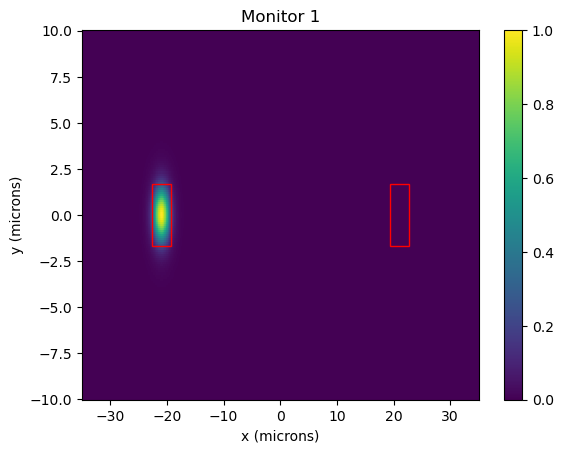

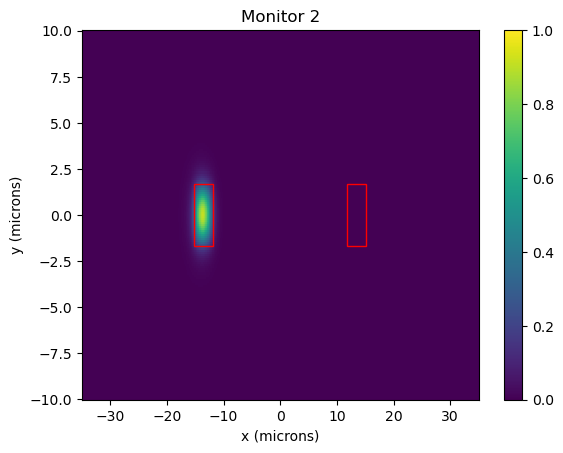

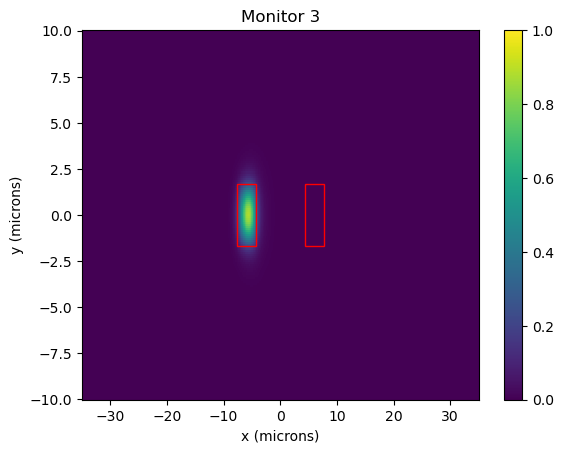

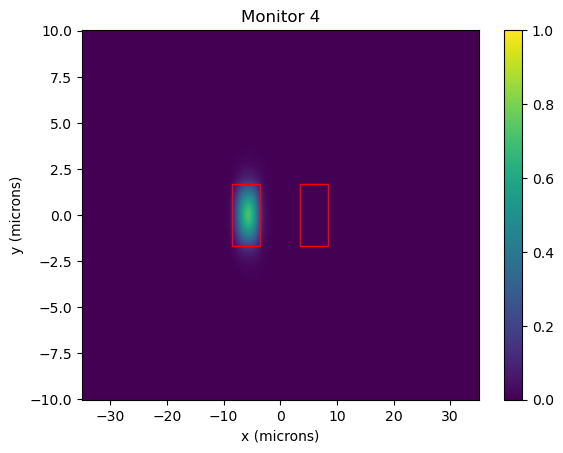

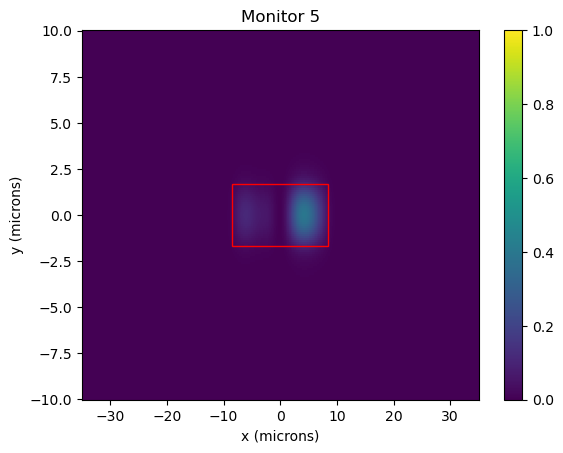

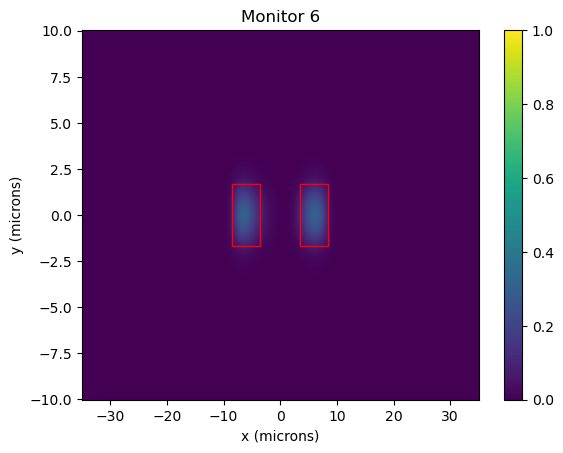

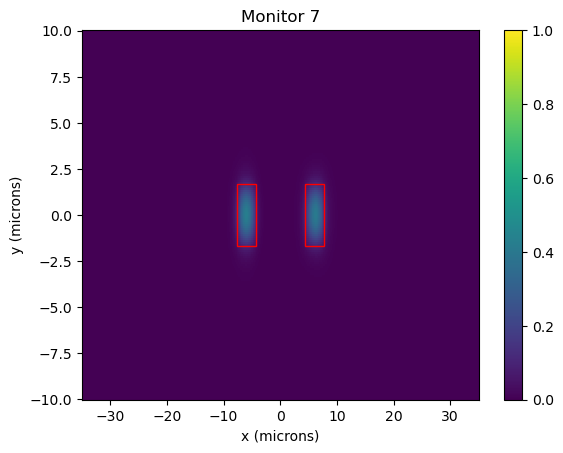

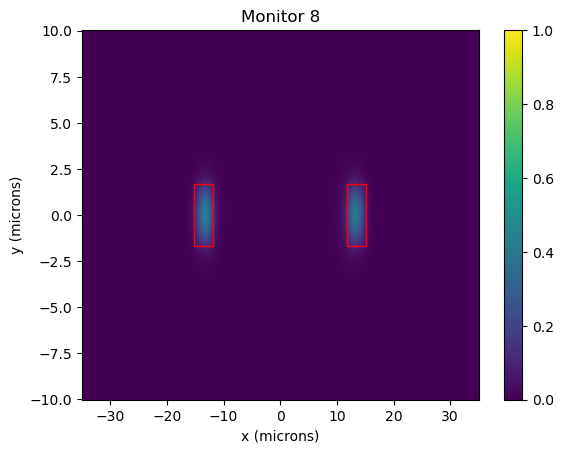

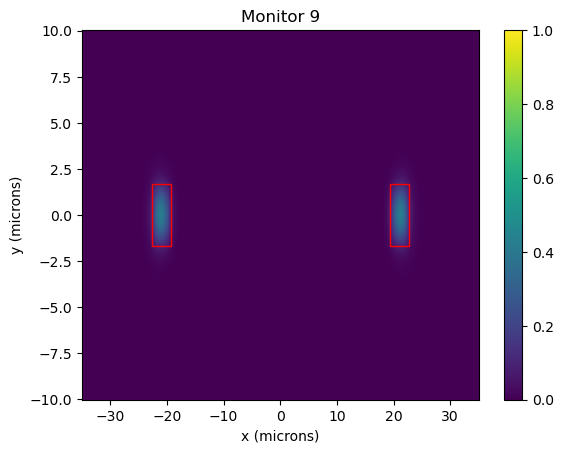

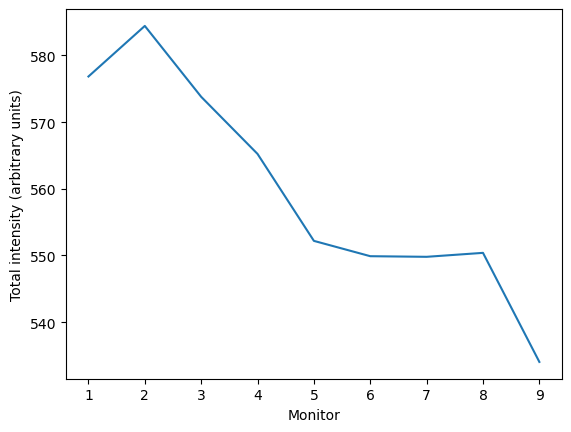

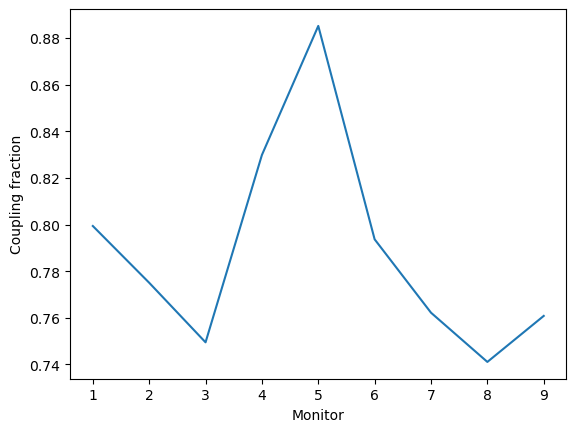

In [97]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = ""

total_powers = []
waveguides = [[[tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[tricoupler_left_x+BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height], [(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height]],
              [[-MMISlabWidth/2, 0-waveguide_height/2, MMISlabWidth, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height], [(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[tricoupler_left_x+BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]]]
coupled = []
output_A, output_B = [], []
for i, monitor in enumerate(np.arange(10, 19)):
    filename = working_dir+save_dir+f"\\2x2MMI_OneInput_GUI_m{monitor}_ex.dat"
    data = np.genfromtxt(filename, delimiter='', skip_header=4).T
    ex_amp = data[::2]
    ex_phase = data[1::2]
    Ex = ex_amp*np.exp(1j*ex_phase*np.pi/180)

    filename = working_dir+save_dir+f"\\2x2MMI_OneInput_GUI_m{monitor}_ey.dat"
    data = np.genfromtxt(filename, delimiter='', skip_header=4).T
    ey_amp = data[::2]
    ey_phase = data[1::2]
    Ey = ey_amp*np.exp(1j*ey_phase*np.pi/180)

    filename = working_dir+save_dir+f"\\2x2MMI_OneInput_GUI_m{monitor}_ez.dat"
    data = np.genfromtxt(filename, delimiter='', skip_header=4).T
    ez_amp = data[::2]
    ez_phase = data[1::2]
    Ez = ez_amp*np.exp(1j*ez_phase*np.pi/180)
    
    intensity = np.absolute(Ex)**2 + np.absolute(Ey)**2 + np.absolute(Ez)**2
    
    x_line = linecache.getline(filename, 3)
    y_line = linecache.getline(filename, 4)
    x_line_split = x_line.split(' ')
    y_line_split = y_line.split(' ')
    x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
    y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

    total_powers.append(intensity.sum())
    
    fig, ax = plt.subplots()
    im = plt.pcolormesh(x, y, intensity, vmin=0, vmax=1)#, norm=LogNorm(vmin=1e-7, vmax=1))
    in_waveguides = 0 
    tot_intensity = np.copy(np.sum(intensity))
    for o, waveguide in enumerate(waveguides[i]):
        patch = patches.Rectangle((waveguide[0], waveguide[1]), waveguide[2], waveguide[3],
                                linewidth=1, edgecolor='r', facecolor='none')
        ax.add_patch(patch)
        field_x = abs(x-(waveguide[0] + waveguide[2]/2)) < waveguide[2]/2.
        field_y = abs(y-(waveguide[1] + waveguide[3]/2)) < waveguide[3]/2.
        in_waveguides += np.sum(intensity[np.ix_(field_y, field_x)])/tot_intensity
        if (o==0 and len(waveguides[i])==2):
            output_A.append(np.sum(intensity[np.ix_(field_y, field_x)])/tot_intensity)
        elif (o==1 and len(waveguides[i])==2):
            output_B.append(np.sum(intensity[np.ix_(field_y, field_x)])/tot_intensity)
    coupled.append(in_waveguides)

    plt.xlabel('x (microns)')
    plt.ylabel('y (microns)')
    plt.colorbar(im)
    plt.title(f"Monitor {i+1}")
    plt.show()


plt.figure()
plt.plot(np.arange(1,10), total_powers)
plt.xlabel('Monitor')
plt.ylabel('Total intensity (arbitrary units)')
plt.show()

plt.figure()
plt.plot(np.arange(1,10), coupled)
plt.xlabel('Monitor')
plt.ylabel('Coupling fraction')
plt.show()

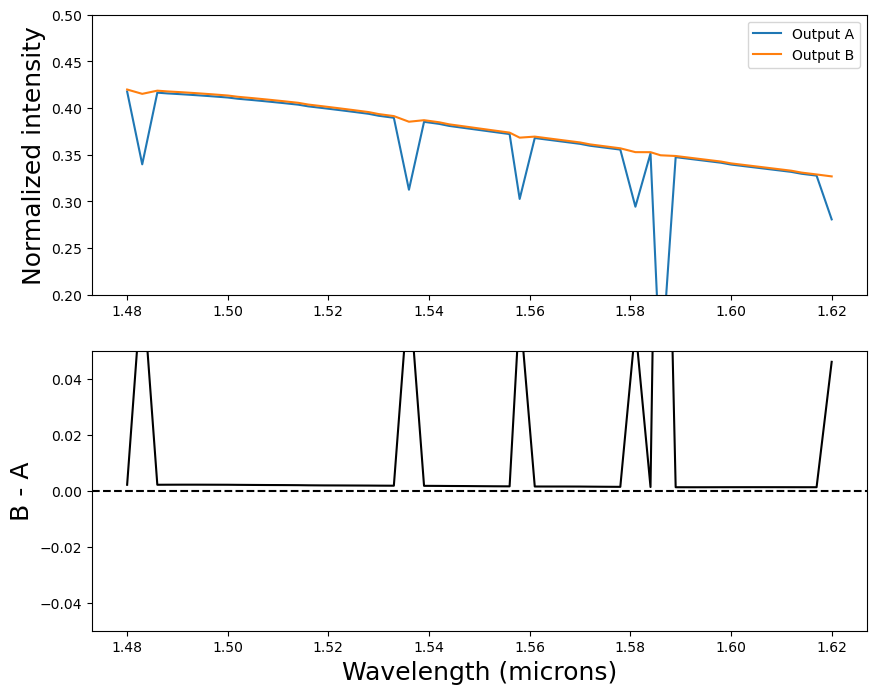

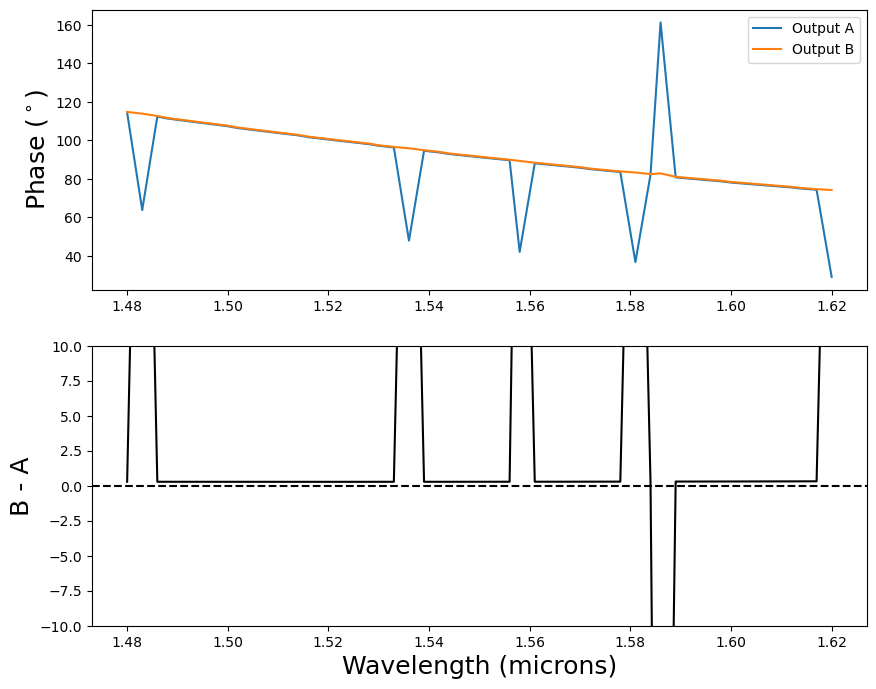

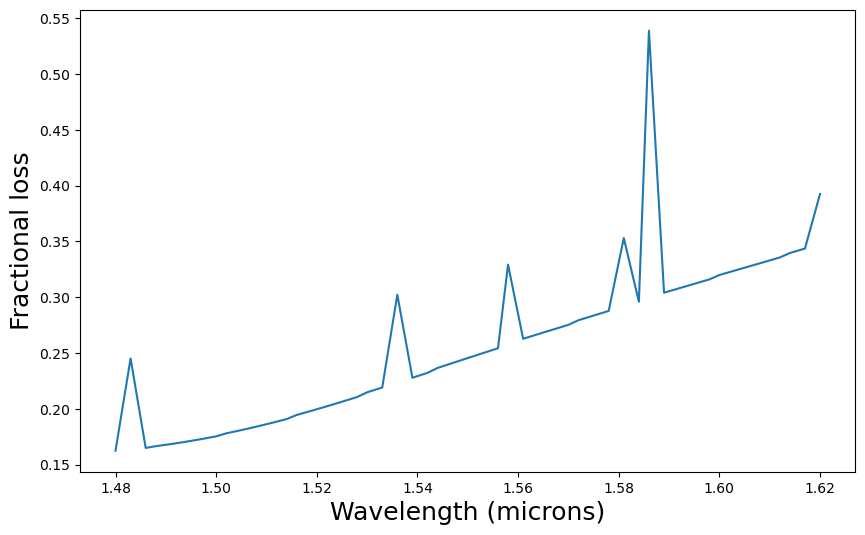

In [13]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\1x2MMI\\"
save_dir = "1x2MMI_scan_Wav"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"
norm_filename = norm_dir+f"StraightWaveguide_scan_Wav1p550.mon"
norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
norm = norm_mon[-1, 1]

filenames_mon = glob.glob(working_dir+save_dir+"\*[0-9].mon")
wav, power_A, power_B, phase_A, phase_B = [], [], [], [], []

for filename in filenames_mon:
    data = np.genfromtxt(filename, delimiter='', skip_header=5)
    wav.append(float(filename.split('Wav')[-1].split('.')[0].replace('p', '.')))
    power_A.append(data[-1, 1])
    power_B.append(data[-1, 2])
    phase_A.append(data[-1, 3])
    phase_B.append(data[-1, 4])
wav, power_A, power_B, phase_A, phase_B = np.array(wav), np.array(power_A)/norm, np.array(power_B)/norm, np.array(phase_A), np.array(phase_B)
# phase_A[phase_A>180] = phase_A[phase_A>180] - 360
# phase_B[phase_B>180] = phase_B[phase_B>180] - 360

# Plot power from all outputs
fontsize = 18
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(nrows=2, ncols=1, height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0])
ax1.plot(wav, power_A, label='Output A')
ax1.plot(wav, power_B, label='Output B')
ax1.set_ylim(0.2, 0.5)
ax1.set_ylabel('Normalized intensity', fontsize=fontsize)
ax1.legend()

ax2 = fig.add_subplot(gs[1], sharex=ax1) # Optional: share the x-axis for alignment
ax2.plot(wav, power_B - power_A, color='k')
ax2.axhline(0, linestyle='dashed', color='black')
ax2.set_ylim(-0.05, 0.05)
ax2.set_ylabel('B - A', fontsize=fontsize)
ax2.set_xlabel('Wavelength (microns)', fontsize=fontsize)
plt.show()

# Plot phase from all outputs
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(nrows=2, ncols=1, height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0])
ax1.plot(wav, phase_A, label='Output A')
ax1.plot(wav, phase_B, label='Output B')
ax1.set_ylabel(r'Phase ($^\circ$)', fontsize=fontsize)
ax1.legend()

ax2 = fig.add_subplot(gs[1], sharex=ax1) # Optional: share the x-axis for alignment
ax2.plot(wav, phase_B - phase_A, color='k')
ax2.axhline(0, linestyle='dashed', color='black')
ax2.set_ylim(-10, 10)
ax2.set_ylabel('B - A', fontsize=fontsize)
ax2.set_xlabel('Wavelength (microns)', fontsize=fontsize)
plt.show()

# Plot loss
fig, ax = plt.subplots(1, 1, figsize=(10,6))
plt.plot(wav, 1 - (power_A + power_B))
plt.xlabel('Wavelength (microns)', fontsize=fontsize)
plt.ylabel('Fractional loss', fontsize=fontsize)
plt.show()


Final throughput: 0.9264532405830433


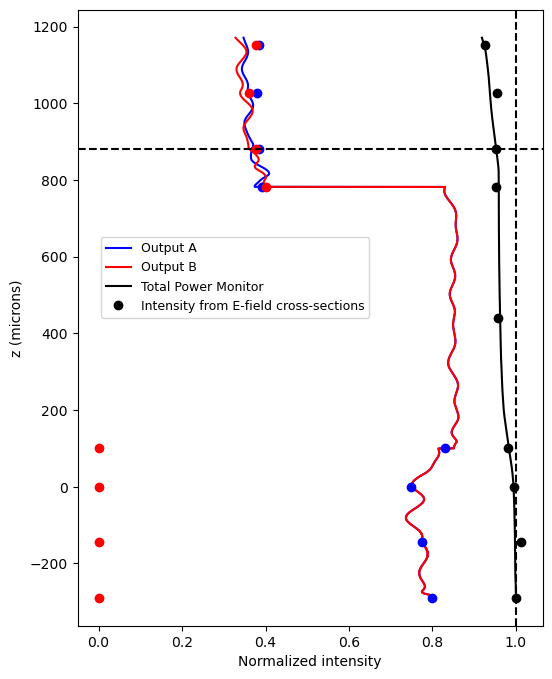

In [163]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI"
save_dir = ""
filename = working_dir+save_dir+'\\2x2MMI_OneInput_GUI.mon'
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"

data = np.genfromtxt(filename, delimiter='', skip_header=5)
z = data[:, 0]
power_A = data[:, 1]
power_B = data[:, 2]
power_tot = data[:, -1]

norm_filename = norm_dir+f"StraightWaveguide_scan_Wav1p550.mon"
norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
norm = norm_mon[-1, 1]

z_mon = [-BendLength, -BendLength/2, 0, TaperLength, TaperLength+(MMISlabLength/2), TaperLength+MMISlabLength, 2*TaperLength+MMISlabLength,
         2*TaperLength+MMISlabLength+BendLength/2, 2*TaperLength+MMISlabLength+BendLength-20]
total_powers = np.array(total_powers)

z_ind = np.argmin(abs(z-(z_mon[-3])))
print('Final throughput:', (power_A[z_ind] + power_B[z_ind])/norm)

plt.figure(figsize=(6,8))
plt.plot(power_A, z, 'b', label='Output A')
plt.plot(power_B, z, 'r', label='Output B')
# plt.plot(power_A + power_B, z, label='Sum')
plt.plot(power_tot, z, 'k', label='Total Power Monitor')
plt.plot(total_powers/total_powers[0], z_mon, 'ko', label='Intensity from E-field cross-sections')
plt.plot(output_A, np.hstack([z_mon[:4], z_mon[-4:]]), 'bo')
plt.plot(output_B, np.hstack([z_mon[:4], z_mon[-4:]]), 'ro')
plt.axvline(1, linestyle='dashed', color='k')
plt.axhline(z[z_ind], linestyle='dashed', color='k')
plt.xlabel('Normalized intensity')
plt.ylabel('z (microns)')
plt.legend(loc=(0.05, 0.5), fontsize=9)
plt.show()



In [165]:
power_A[0], norm

(0.8003888, 0.7847307)